# Convex Lightcurve Inversion

Implements the convex inversion approach of Kaasalainen & Torppa (2001):

1. **Forward model**: brightness `L = A @ g` where `g_j` are face areas and `A_ij = S(μ_j, μ0_j)` is the scattering function (linear in `g`).
2. **Exponential parametrisation**: `g_j = exp(a_j)` enforces positivity without explicit constraints.
3. **Inversion**: minimise renormalised χ² over `a_j` with `scipy.optimize.least_squares`.
4. **Reconstruction**: Minkowski minimisation via the dual transform to recover a convex mesh, exported as `.stl`.

In [1]:
try:
    import cupy as cp
    CUPY_AVAILABLE = True
except ImportError:
    CUPY_AVAILABLE = False

import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull
from stl import mesh as stl_mesh
import trimesh
import pyvista as pv
pv.set_jupyter_backend('html')

from hac.data import get_model_stl_path, load_data
from hac.constants import CAMERA_ANGLE_ALPHA
from hac.convex_forward import get_unit_vectors#, convex_forward_model_gpu
from hac.mesh import normalize_mesh_to_challenge_cylinder
from hac.eval import calculate_voxel_measure

asteroid = 2

if asteroid == 1:
    R_cylinder = 1.12
elif asteroid == 2:
    R_cylinder = 1.42
elif asteroid == 3:
    R_cylinder = 0.88

## 1. Ellipsoidal shape prior (cylinder-constrained icosphere)

The asteroid is assumed to lie between planes **z = −1** and **z = 1**, with
non-empty intersection with both planes, and to be contained in the cylinder
**D(0, R) × [−1, 1]** where D(0, R) is the disc of radius R in the xy-plane. (Different for each asteroid)

The unit-sphere icosphere is rescaled to the ellipsoid with semi-axes (R, R, 1),
which is the largest body of that family fitting inside the cylinder. Face normals
and areas are recomputed on the scaled surface.

In [22]:
sphere_mesh = trimesh.creation.icosphere(subdivisions=3)
#sphere_mesh = trimesh.creation.box()
print(f"Using {len(sphere_mesh.faces)} faces")
sphere_bounded = normalize_mesh_to_challenge_cylinder(sphere_mesh,target_R=R_cylinder)
vertices = sphere_bounded.vertices
faces = sphere_bounded.faces

V = np.array(vertices)
F = np.array(faces)

# Face normals and areas
e1 = V[F[:,1]] - V[F[:,0]]
e2 = V[F[:,2]] - V[F[:,0]]
cross = np.cross(e1, e2)
mag   = np.linalg.norm(cross, axis=1)
normals = cross / mag[:, None]
sphere_areas   = 0.5 * mag
n_facets = len(sphere_areas)

faces_with_count = np.hstack([
    np.full((faces.shape[0], 1), 3, dtype=faces.dtype),
    faces
])
mesh_pyvista = pv.PolyData(vertices, faces_with_count)

# Visualize the mesh
mesh_pyvista.plot(show_axes=True)

Using 1280 faces


EmbeddableWidget(value='<iframe srcdoc="<!doctype html>\n<html lang=&quot;en&quot;>\n  <head>\n    <meta chars…

## 2. Load observed lightcurve

### Remove duplicated blender data

In [23]:
CAMERA_ANGLE_ALPHA_REM_DUPLICATES: dict[str, float] = {
    "0_hor1": 0.0, 
    "0_top": 21.0,
    "0_bottom": -21.0,
    "45_hor1": 0.0,
    "45_top": 26.0,
    "45_bottom": -24.0,
    "90_hor1": 0.0,
    "90_top": 26.0,
    "90_bottom": -24.0,
    "135_hor1": 0.0,
    "135_top": 26.0,
    "135_bottom": -24.0,
    "225_hor1": 0.0,
    "225_top": 24.0,
    "225_bottom": -26.0,
    "270_hor1": 0.0,
    "270_top": 24.0,
    "270_bottom": -26.0,
    "315_hor1": 0.0,
    "315_top": 24.0,
    "315_bottom": -26.0
}

In [24]:
ds_blender = load_data(asteroid, "simulated", "intensity")
cam_keys   = list(CAMERA_ANGLE_ALPHA_REM_DUPLICATES.keys())
n_cams     = len(cam_keys)
n_phases   = 360
phases     = np.linspace(0, 2 * np.pi, n_phases, endpoint=False)

e_sun          = np.array([-1.0, 0.0, 0.0])
lambert_weight = 0.5   # LSL: S = mu*mu0/(mu+mu0) + lw*mu*mu0

obs_norm = np.empty((n_cams, n_phases))
for i, cam in enumerate(cam_keys):
    lc = ds_blender.data[cam].values.astype(np.float64)
    obs_norm[i] = lc# / lc.mean() # skip normalization since this is already done

print(f"Observations: {n_cams} cameras × {n_phases} phases = {n_cams * n_phases} data points")

Observations: 21 cameras × 360 phases = 7560 data points


## 3. Build forward matrix A

`A[i·n_phases + t, j] = S(μ_j(t), μ0_j(t))` — scattering contribution of facet `j`
at rotation phase `t` for camera `i`. With fixed normals, brightness is **linear** in `g`.

In [25]:
cos_p = np.cos(phases)  
sin_p = np.sin(phases)

A_blocks = []
for cam in cam_keys:
    phi_deg   = float(cam.split("_")[0])
    alpha_deg = CAMERA_ANGLE_ALPHA_REM_DUPLICATES[cam]
    _, e_obs  = get_unit_vectors(phi_deg, alpha_deg)
    e_obs     = np.asarray(e_obs, dtype=np.float64)

    # Rotate sun & observer through rotational phase (z-axis rotation)
    e_sun_rot = np.column_stack([
        cos_p * e_sun[0] - sin_p * e_sun[1],
        sin_p * e_sun[0] + cos_p * e_sun[1],
        np.full(n_phases, e_sun[2])
    ])  # (n_phases, 3)
    e_obs_rot = np.column_stack([
        cos_p * e_obs[0] - sin_p * e_obs[1],
        sin_p * e_obs[0] + cos_p * e_obs[1],
        np.full(n_phases, e_obs[2])
    ])  # (n_phases, 3)

    mu0  = e_sun_rot @ normals.T   # (n_phases, n_facets)
    mu   = e_obs_rot @ normals.T   # (n_phases, n_facets)
    mask = (mu0 > 0) & (mu > 0)

    # LSL scattering law (eq. 2 of doi:10.48550/arXiv.2502.16455)
    # np.maximum avoids 0/0 when both mu and mu0 are zero (mask=False there anyway)
    S = np.where(mask, mu * mu0 / np.maximum(mu + mu0, 1e-30) + lambert_weight * mu * mu0, 0.0)
    A_blocks.append(S)

A      = np.vstack(A_blocks)              # (n_cams * n_phases, n_facets)
A_3d   = A.reshape(n_cams, n_phases, n_facets)
A_mean = A_3d.mean(axis=1)               # (n_cams, n_facets)  — per-camera mean

print(f"Forward matrix A: {A.shape}  ({A.nbytes / 1e6:.1f} MB)")

Forward matrix A: (7560, 1280)  (77.4 MB)


## 4. Least-squares inversion

Minimise the normalised χ², with a convexity regularisation term added as in
eq. (11) of Kaasalainen & Torppa (2001) (the albedo term of that equation is
dropped since we don't solve for albedo here):
$$\chi^2_{\rm ren} = \sum_i \left\|\frac{L^{(i)}}{\bar L^{(i)}} - \frac{A^{(i)}\mathbf{g}}{\overline{A^{(i)}\mathbf{g}}}\right\|^2
+ \lambda_s \sum_{i=1}^{3}\left[\sum_j n_j^{(i)} g_j\right]^2, \quad g_j = e^{a_j}$$

The regularisation term penalises the length of the facet-normal-weighted area
vector $\sum_j n_j g_j$ (eq. 3): it vanishes exactly for a closed convex polyhedron,
so it pulls the (otherwise unconstrained) exponential parametrisation toward
convex solutions

In [27]:
optimizer = "cg"
lambda_s  = 0.2   # convexity regularisation weight (eq. 11, shape term only)

# Move matrices to GPU once; fall back to NumPy if CuPy is unavailable.
if CUPY_AVAILABLE:
    _xp       = cp
    _A        = cp.asarray(A)
    _A_3d     = cp.asarray(A_3d)
    _A_mean   = cp.asarray(A_mean)
    _obs_norm = cp.asarray(obs_norm)
    _normals  = cp.asarray(normals)
else:
    _xp       = np
    _A        = A
    _A_3d     = A_3d
    _A_mean   = A_mean
    _obs_norm = obs_norm
    _normals  = normals
    print("CuPy unavailable — using NumPy CPU backend")

_use_gpu = (_xp is not np)


def matrix_residuals_and_jac(a):
    """Full residual vector + Jacobian for Levenberg–Marquardt.

    Appends 3 synthetic residuals sqrt(lambda_s) * (sum_j n_j g_j) with target
    zero (eq. 11, shape term only) to enforce convexity as a regularisation.

    Memory: O(n_obs × n_facets) — avoid for n_facets ≳ 500.
    """
    g    = _xp.exp(_xp.asarray(a))
    Ag   = _A @ g                                        # (n_cams * n_phases,)
    Ag3d = Ag.reshape(n_cams, n_phases)
    m    = Ag3d.mean(axis=1)                             # (n_cams,)

    norm_model = Ag3d / m[:, None]
    res        = _obs_norm - norm_model

    J = -(g[None, None, :] / m[:, None, None]) * (
        _A_3d - norm_model[:, :, None] * _A_mean[:, None, :]
    )  # (n_cams, n_phases, n_facets)

    sqrt_ls    = _xp.sqrt(lambda_s)
    conv_vec   = _normals.T @ g                          # (3,)
    res_conv   = sqrt_ls * conv_vec                       # (3,)
    J_conv     = sqrt_ls * (_normals * g[:, None]).T      # (3, n_facets)

    res_full = _xp.concatenate([res.ravel(), res_conv])
    J_full   = _xp.concatenate([J.reshape(n_cams * n_phases, n_facets), J_conv], axis=0)

    if _use_gpu:
        return res_full.get(), J_full.get()
    return res_full, J_full


def cost_and_grad(a):
    """Scalar cost + gradient for L-BFGS / CG.

    Computes J^T r without ever materialising the full (n_obs × n_facets)
    Jacobian.  Memory stays O(n_obs + n_facets) regardless of n_facets.
    Adds the convexity regularisation term of eq. (11) (shape term only):
    lambda_s * ||sum_j n_j g_j||^2.

    Derivation:
      f = 0.5 ||r||^2,   r[i,t] = obs[i,t] - Ag[i,t]/m_i
      df/da_k = -g_k * ( term1[k] - term2[k] )
        term1[k] = Σ_{i,t} (r[i,t]/m_i) * A[i·T+t, k]   = A.T @ (r/m).ravel()
        term2[k] = Σ_i A_mean[i,k] * Σ_t r[i,t]·nm[i,t] / m_i
      reg = lambda_s * ||conv_vec||^2,  conv_vec = normals.T @ g
      dreg/da_k = 2 * lambda_s * g_k * (normals @ conv_vec)[k]
    """
    g    = _xp.exp(_xp.asarray(a, dtype=_xp.float64))
    Ag   = _A @ g
    Ag3d = Ag.reshape(n_cams, n_phases)
    m    = Ag3d.mean(axis=1)

    norm_model = Ag3d / m[:, None]
    res        = _obs_norm - norm_model                  # (n_cams, n_phases)

    cost = float(0.5 * _xp.dot(res.ravel(), res.ravel()))
    if _use_gpu and hasattr(cost, 'get'):
        cost = cost.get()

    term1 = _A.T @ (res / m[:, None]).ravel()           # (n_facets,)
    term2 = _A_mean.T @ (_xp.sum(norm_model * res, axis=1) / m)  # (n_facets,)
    grad  = -g * (term1 - term2)

    conv_vec = _normals.T @ g                            # (3,)
    cost    += float(lambda_s * _xp.dot(conv_vec, conv_vec))
    grad    += 2.0 * lambda_s * g * (_normals @ conv_vec)

    if _use_gpu:
        return float(cost), grad.get().astype(np.float64)
    return float(cost), np.asarray(grad, dtype=np.float64)


# ---------------------------------------------------------------------------
# Run inversion
# ---------------------------------------------------------------------------
from scipy.optimize import least_squares, minimize

a_init = np.log(sphere_areas)   # warm start: ellipsoidal prior face areas

if optimizer == "lm":
    print(f"Running Levenberg–Marquardt  (n_params={n_facets})...")
    result = least_squares(
        lambda a: matrix_residuals_and_jac(a)[0],
        a_init,
        jac=lambda a: matrix_residuals_and_jac(a)[1],
        method="lm",
        ftol=1e-10, xtol=1e-10,
        max_nfev=1000,
        verbose=2,
    )
    a_opt = result.x
    print(f"\n{result.message}")
    print(f"Cost: {result.cost:.6f}")

elif optimizer in ("lbfgs", "cg"):
    sci_method = {"lbfgs": "L-BFGS-B", "cg": "CG"}[optimizer]
    print(f"Running {sci_method}  (n_params={n_facets})...")

    _iter = [0]
    def _cb(a):
        _iter[0] += 1
        if _iter[0] % 1000 == 0:
            c, _ = cost_and_grad(a)
            print(f"  iter {_iter[0]:4d}: cost = {c:.6f}")

    result = minimize(
        cost_and_grad,
        a_init,
        jac=True,          # function returns (f, grad) tuple
        method=sci_method,
        callback=_cb,
        options={"maxiter": 20000, "gtol": 1e-9},
    )
    a_opt = result.x
    print(f"\n{result.message}")
    print(f"Cost: {result.fun:.6f}")

else:
    raise ValueError(f"Unknown optimizer {optimizer!r}. Choose 'lm', 'lbfgs', or 'cg'.")

g_opt = np.exp(a_opt)
print(f"g_j:  min={g_opt.min():.4f}  max={g_opt.max():.4f}  mean={g_opt.mean():.4f}")

conv_vec = normals.T @ g_opt
print(f"Convexity residual |Σ n_j g_j| / Σ g_j = {np.linalg.norm(conv_vec)/g_opt.sum():.4e}")

Running CG  (n_params=1280)...
  iter 1000: cost = 850.626958
  iter 2000: cost = 840.554457
  iter 3000: cost = 839.887418
  iter 4000: cost = 839.705714
  iter 5000: cost = 839.586230
  iter 6000: cost = 839.503694
  iter 7000: cost = 839.495285
  iter 8000: cost = 839.452794
  iter 9000: cost = 839.442750
  iter 10000: cost = 839.440899
  iter 11000: cost = 839.436417
  iter 12000: cost = 839.433129
  iter 13000: cost = 839.428567
  iter 14000: cost = 839.423515
  iter 15000: cost = 839.407511
  iter 16000: cost = 839.402997
  iter 17000: cost = 839.400245
  iter 18000: cost = 839.399114
  iter 19000: cost = 839.397102
  iter 20000: cost = 839.396108

Maximum number of iterations has been exceeded.
Cost: 839.396108
g_j:  min=0.0010  max=4604.7126  mean=27.1836
Convexity residual |Σ n_j g_j| / Σ g_j = 2.4000e-07


## 5. Lightcurve fit quality

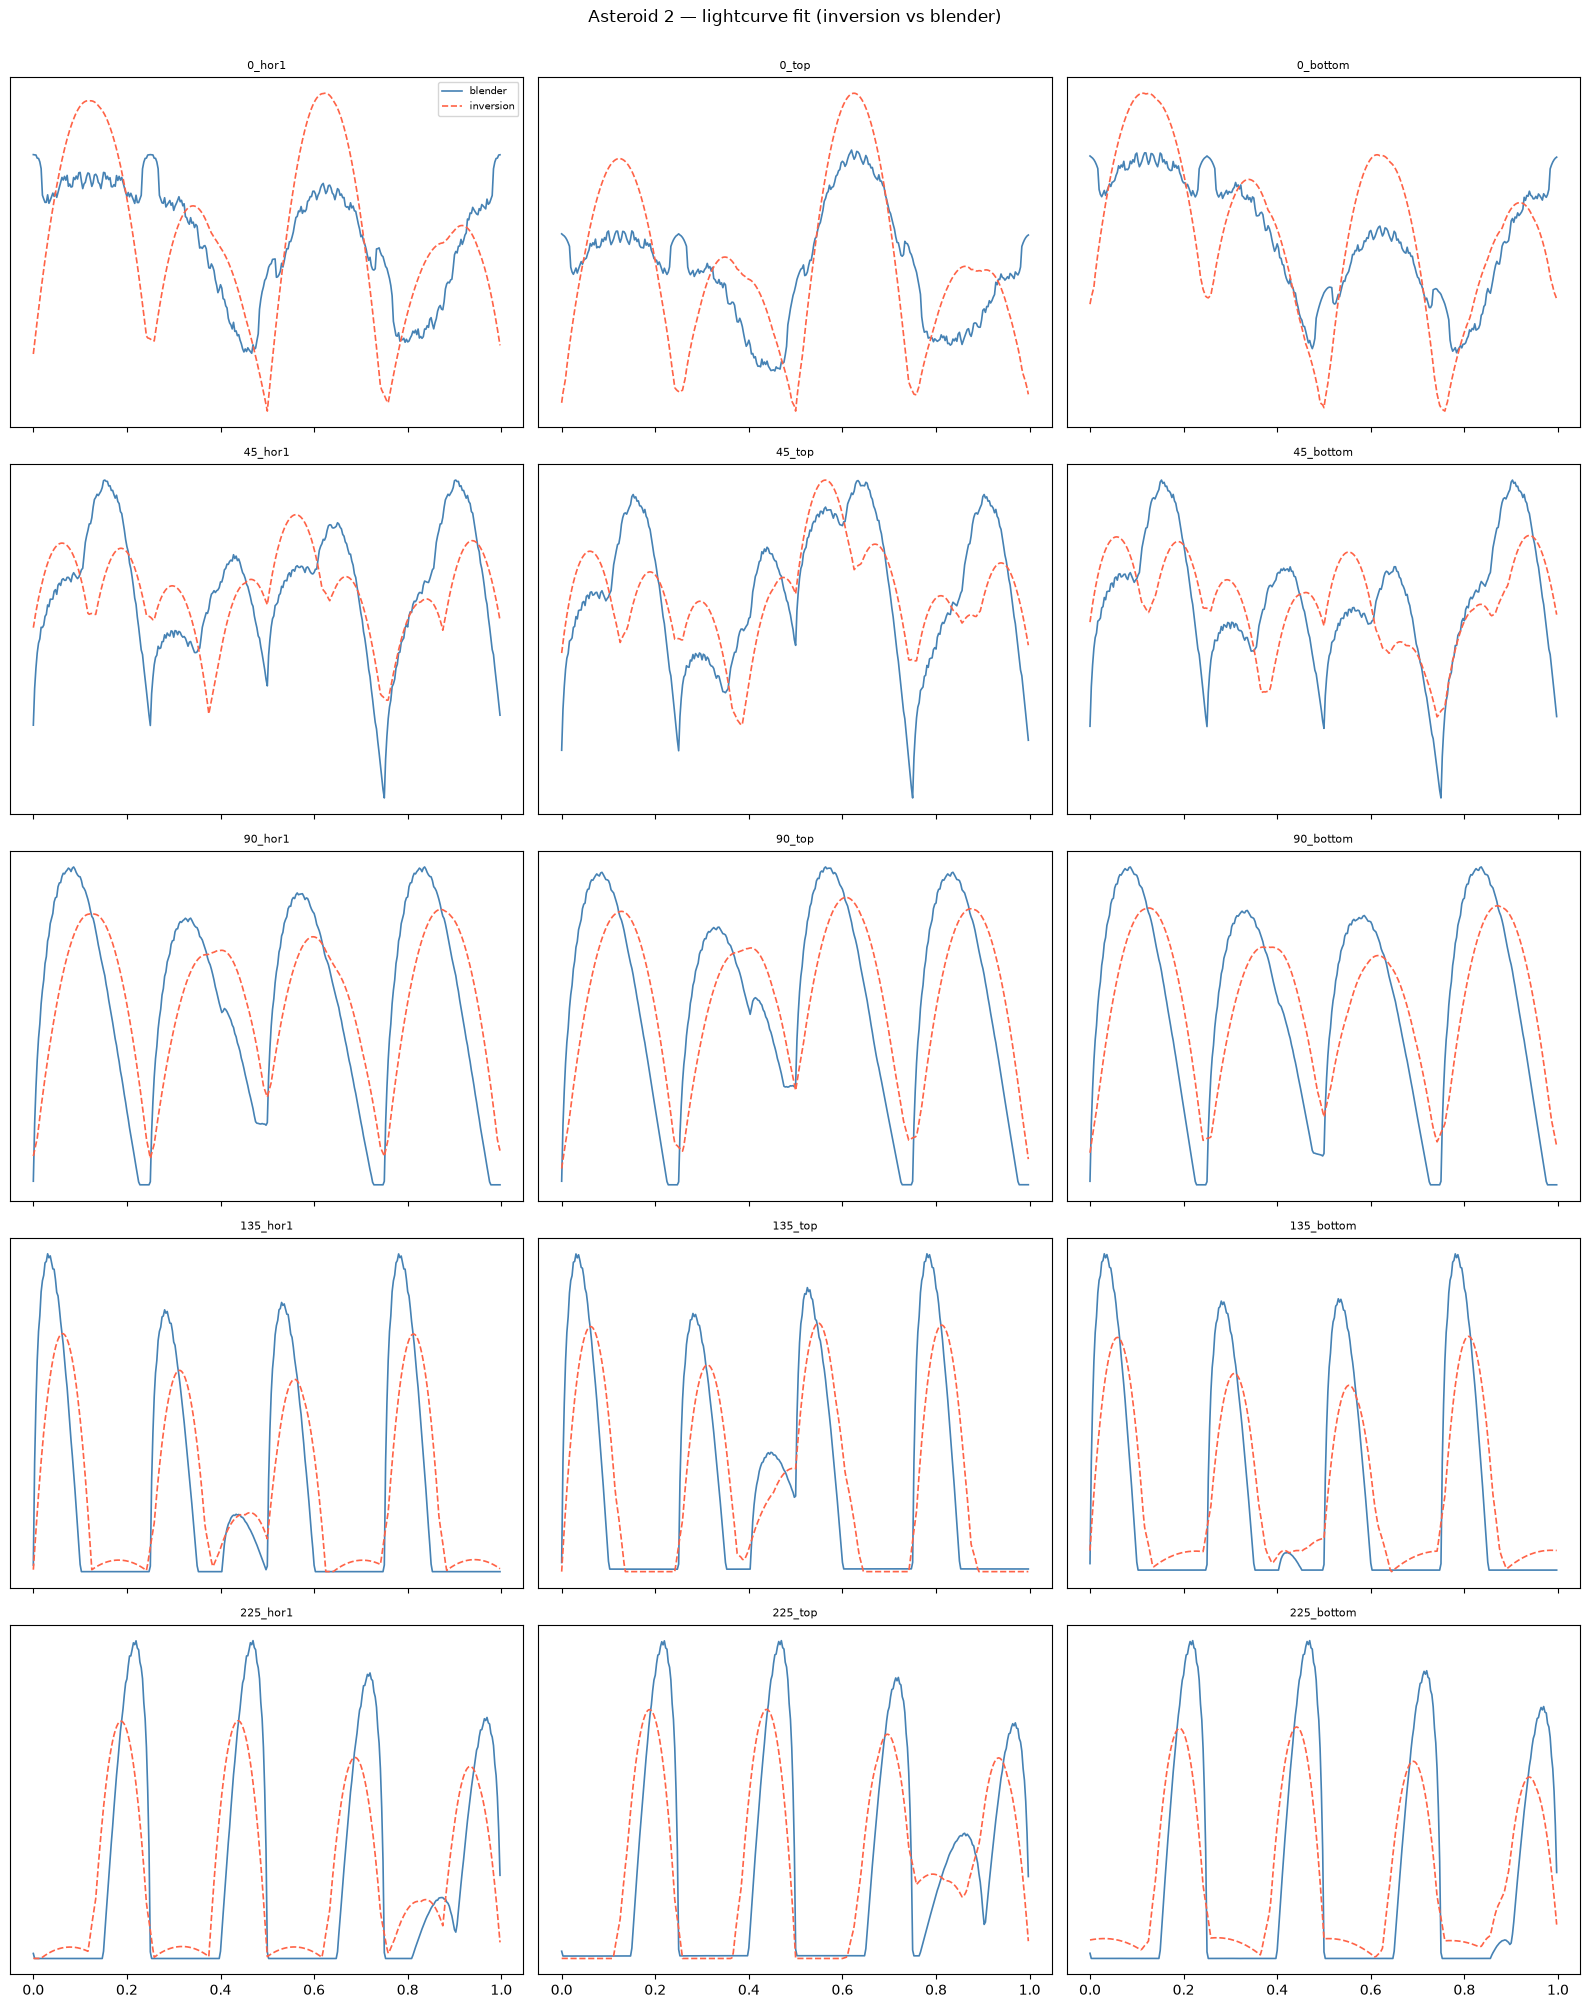

Overall MSE (normalised): 0.222062


In [28]:
Ag_opt     = (A @ g_opt).reshape(n_cams, n_phases)
pred_norm  = Ag_opt / Ag_opt.mean(axis=1, keepdims=True)
phase_axis = np.linspace(0, 1, n_phases, endpoint=False)

fig, axes = plt.subplots(5, 3, figsize=(16, 20), sharex=True)
for ax, cam, i in zip(axes.ravel(), cam_keys, range(n_cams)):
    ax.plot(phase_axis, obs_norm[i],  lw=1.2, color="steelblue", label="blender")
    ax.plot(phase_axis, pred_norm[i], lw=1.2, color="tomato",    label="inversion", ls="--")
    ax.set_title(cam, fontsize=8)
    ax.set_yticks([])

axes[0, 0].legend(fontsize=7)
fig.suptitle(f"Asteroid {asteroid} — lightcurve fit (inversion vs blender)", y=1.002)
fig.tight_layout()
plt.show()

print(f"Overall MSE (normalised): {np.mean((obs_norm - pred_norm)**2):.6f}")

## 6. Remove small areas and include dark area to enforce convexity

In [ ]:
# Remove small areas
area_threshold = 1e-3 * g_opt.mean()   # facets with area below this are dropped

keep_mask = g_opt >= area_threshold
n_removed = keep_mask.size - int(keep_mask.sum())

g_opt   = g_opt[keep_mask]
normals = normals[keep_mask]

print(f"Removed {n_removed}/{keep_mask.size} facets with area < {area_threshold:.3e} "
      f"({100 * n_removed / keep_mask.size:.2f}%)")
print(f"g_j after filtering: min={g_opt.min():.4f}  max={g_opt.max():.4f}  n={g_opt.size}")

# Dark facet check (Kaasalainen & Torppa 2001, eq. 3 closure condition).

conv_vec   = np.array([normals.T @ g_opt])          # Σ_j g_j n_j — closure residual
dark_area  = np.linalg.norm(conv_vec)   # area of the fictitious closing facet
total_area = g_opt.sum()
dark_pct   = dark_area / total_area * 100

print(f"Total area:      {total_area:.6f}")
print(f"Dark facet area: {dark_area:.6f}  ({dark_pct:.4f}% of total)")

assert dark_pct < 1.0, (
    f"Dark facet area is {dark_pct:.2f}% of total area (>= 1%); "
    "increase lambda_s to enforce convexity more strongly."
)
print("Dark area < 1% of total area — convexity constraint satisfied.")

# Adding dark area to solution
normals_wdark = np.concatenate([normals,-conv_vec/dark_area])
g_wdark = np.concatenate([g_opt,np.array([dark_area])])

Removed 1027/1280 facets with area < 2.718e-02 (80.23%)
g_j after filtering: min=0.0273  max=4604.7126  n=253
Total area:      34784.352496
Dark facet area: 0.313214  (0.0009% of total)
Dark area < 1% of total area — convexity constraint satisfied.


## 7. Shape reconstruction via Minkowski minimisation

In [31]:
from pathlib import Path
from hac.minkowski import minkowski_reconstruct, build_convex_mesh, save_stl

vertices_cloud = minkowski_reconstruct(g_wdark, normals_wdark, verbose=True,epsilon=0.001)
mesh_verts, mesh_faces = build_convex_mesh(vertices_cloud)
print(f"Reconstructed convex mesh: {len(mesh_verts)} vertices, {len(mesh_faces)} faces")

out_path = Path(f"/zhome/95/1/155570/HAC-DTU/workspaces/christian/stls/ast{asteroid}_convex_inversion.stl")
save_stl(mesh_verts, mesh_faces, out_path)
print(f"Saved STL to {out_path.resolve()}")

  iter    50: volume=2198673.874080 alphak=0.156406
  iter   100: volume=2335400.337105 alphak=0.090080
  iter   150: volume=2399544.525971 alphak=0.061647
  iter   200: volume=2439458.036734 alphak=0.046706
  iter   250: volume=2465233.811248 alphak=0.059952
  iter   300: volume=2481625.488887 alphak=0.033298
  iter   350: volume=2492970.879146 alphak=0.048122
  iter   400: volume=2500168.726017 alphak=0.019897
  iter   450: volume=2505737.701159 alphak=0.031253
  iter   500: volume=2509901.502878 alphak=0.014253
  iter   550: volume=2512727.362605 alphak=0.016027
  iter   600: volume=2514984.216410 alphak=0.013731
  iter   650: volume=2516514.018214 alphak=0.008527
  iter   700: volume=2517725.923493 alphak=0.020581
  iter   750: volume=2518647.153702 alphak=0.006195
  iter   800: volume=2519299.408127 alphak=0.006549
  iter   850: volume=2519789.036537 alphak=0.004642
  iter   900: volume=2520178.168012 alphak=0.004020
  iter   950: volume=2520481.335245 alphak=0.003484
  iter  1000

## Comparison with ground truth (after normalizing to bounding cylinder)

In [37]:
bounded_gt = normalize_mesh_to_challenge_cylinder(trimesh.load_mesh(get_model_stl_path(asteroid)),target_R=R_cylinder)
bounded_rec = normalize_mesh_to_challenge_cylinder(trimesh.load_mesh(out_path),target_R=R_cylinder)

bounded_gt.export("/zhome/95/1/155570/HAC-DTU/workspaces/christian/stls/ast2_gt_bounded.stl")
bounded_rec.export("/zhome/95/1/155570/HAC-DTU/workspaces/christian/stls/ast2_convex_inversion_bounded.stl")

solb_pyvista = pv.read("/zhome/95/1/155570/HAC-DTU/workspaces/christian/stls/ast2_convex_inversion_bounded.stl")#pv.PolyData(mesh_verts, faces_sol)
solb_pyvista.plot(show_axes=True,show_edges=True)
solb_pyvista = pv.read("/zhome/95/1/155570/HAC-DTU/workspaces/christian/stls/ast2_gt_bounded.stl")#pv.PolyData(mesh_verts, faces_sol)
solb_pyvista.plot(show_axes=True)

print(f"Voxel similiarty: {calculate_voxel_measure(bounded_gt,bounded_rec)}")

EmbeddableWidget(value='<iframe srcdoc="<!doctype html>\n<html lang=&quot;en&quot;>\n  <head>\n    <meta chars…

EmbeddableWidget(value='<iframe srcdoc="<!doctype html>\n<html lang=&quot;en&quot;>\n  <head>\n    <meta chars…

Voxel similiarty: 0.0276980889968379


## Static comparison plot

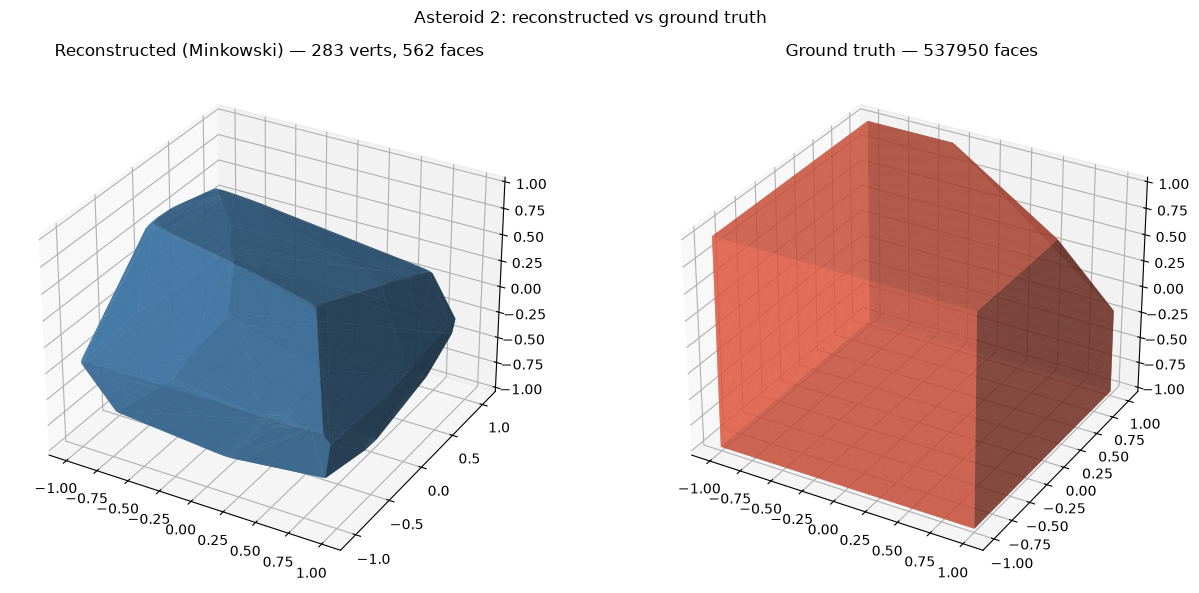

In [ ]:
#gt_stl = stl_mesh.Mesh.from_file(get_model_stl_path(asteroid))
gt_verts = bounded_gt.vertices
rec_verts = bounded_rec.vertices
gt_faces = bounded_gt.faces#np.arange(len(gt_verts)).reshape(-1, 3)
rec_faces = bounded_rec.faces


fig = plt.figure(figsize=(13, 6))

ax1 = fig.add_subplot(1, 2, 1, projection="3d")
ax1.plot_trisurf(rec_verts[:, 0], rec_verts[:, 1], rec_verts[:, 2],
                triangles=rec_faces, alpha=0.8, edgecolor="none", color="steelblue")
ax1.set_title(f"Reconstructed (Minkowski) — {len(mesh_verts)} verts, {len(mesh_faces)} faces")

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot_trisurf(gt_verts[:, 0], gt_verts[:, 1], gt_verts[:, 2],
                triangles=gt_faces, alpha=0.8, edgecolor="none", color="tomato")
ax2.set_title(f"Ground truth — {len(bounded_gt.faces)} faces")

fig.suptitle(f"Asteroid {asteroid}: reconstructed vs ground truth")
plt.tight_layout()
plt.show()